In [55]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import re

df = pd.read_csv("compas-scores-two-years.csv")

features = [
    "age",
    "priors_count",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count",
    "c_charge_degree",
]

interesting_features = [
    "age",
    "sex", "race", 
    "juv_fel_count", 
    "juv_misd_count", 
    "juv_other_count", 
    "priors_count", 
    "c_charge_degree", 
    #"c_charge_desc"
]

# comparison = pd.DataFrame({
#     "original": df["c_charge_desc"].fillna(""),
#     "cleaned": (
#         df["c_charge_desc"]
#         .fillna("")
#         .str.replace(r'[^a-zA-Z]+', '', regex=True)
#         .str.lower()
#     )
# })
# 
# display(comparison["original"].value_counts())
# 
# # Find cleaned descriptions that correspond to multiple original descriptions
# unified = (
#     comparison.groupby("cleaned")["original"]
#     .unique()
#     .reset_index()
# )
# 
# unified["num_originals"] = unified["original"].apply(len)
# 
# # Keep only groups where multiple original descriptions merged
# unified = unified[unified["num_originals"] > 1]
# 
# pd.set_option('display.max_colwidth', None)
# pd.set_option('display.max_rows', None)
# display(unified["original"])

In [56]:
charge_descriptions = (
    df["c_charge_desc"]
    .fillna("")
    .str.lower()
)

counts = charge_descriptions.value_counts()

charge_descriptions = charge_descriptions.apply(
    lambda x: x if counts[x] >= 50 else "other"
)

display(charge_descriptions.value_counts())

df["c_charge_desc"] = charge_descriptions


c_charge_desc
other                                2119
battery                              1156
arrest case no charge                1137
possession of cocaine                 475
grand theft in the 3rd degree         427
driving while license revoked         200
driving under the influence           135
aggravated assault w/dead weap        105
felony battery (dom strang)           100
grand theft (motor vehicle)            99
pos cannabis w/intent sel/del          97
felony driving while lic suspd         96
possess cannabis/20 grams or less      96
burglary unoccupied dwelling           84
burglary conveyance unoccup            77
possession of cannabis                 76
dui property damage/injury             74
poss3,4 methylenedioxymethcath         72
driving license suspended              68
felony petit theft                     68
aggrav battery w/deadly weapon         65
resist officer w/violence              59
susp drivers lic 1st offense           57
dui level 0.15 or mi

In [57]:
df["race"].value_counts()

race
African-American    3696
Caucasian           2454
Hispanic             637
Other                377
Asian                 32
Native American       18
Name: count, dtype: int64

In [58]:

X = df[interesting_features].copy()
catgorical_features = ["c_charge_degree", "sex", "race"] #, "c_charge_desc"

X = pd.get_dummies(X, columns=catgorical_features, drop_first=True)
y = df["two_year_recid"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=67, stratify=y 
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.1%}")

Test accuracy: 67.9%


In [59]:
results = pd.DataFrame({
    "race": df.loc[X_test.index, "race"],
    "sex": df.loc[X_test.index, "sex"],
    "age": df.loc[X_test.index, "age_cat"],
    "actual": y_test,
    "predicted": y_pred,
})

no_new_case = results[results["actual"] == 0]
new_case = results[results["actual"] == 1]
TFPN_names = ["False Positive", "True Negative", "True Positive", "False Negative"]
TFPN_counts = {
    "Race: African-American": [0, 0, 0, 0],
    "Race: Asian": [0, 0, 0, 0],
    "Race: Caucasian": [0, 0, 0, 0],
    "Race: Hispanic": [0, 0, 0, 0],
    "Race: Native American": [0, 0, 0, 0],
    "Race: Other": [0, 0, 0, 0],
    "Sex: Male": [0, 0, 0, 0],
    "Sex: Female": [0, 0, 0, 0],
    "Age: Less than 25": [0, 0, 0, 0],
    "Age: 25 - 45": [0, 0, 0, 0],
    "Age: Greater than 45": [0, 0, 0, 0]
}

# FPR race
print("False Positive Rate (FPR) by race:")
for group in ["African-American", "Asian", "Caucasian", "Hispanic", "Native American", "Other"]:
    group_rows = no_new_case[no_new_case["race"] == group]

    false_positives = (group_rows["predicted"] == 1).sum()
    total = len(group_rows)
    false_positive_rate = false_positives / total
    TFPN_counts[f"Race: {group}"][0] = false_positives
    TFPN_counts[f"Race: {group}"][1] = total - false_positives
    
    print(f"{group} FPR: {false_positives}/{total} = {false_positive_rate:.1%}")

# FPR sex
print("\nFalse Positive Rate (FPR) by sex:")
for group in ["Male", "Female"]:
    group_rows = results[results["sex"] == group]

    false_positives = (group_rows["predicted"] == 1).sum()
    total = len(group_rows)
    false_positive_rate = false_positives / total
    TFPN_counts[f"Sex: {group}"][0] = false_positives
    TFPN_counts[f"Sex: {group}"][1] = total - false_positives

    print(f"{group} FPR: {false_positives}/{total} = {false_positive_rate:.1%}")

# FPR age
print("\nFalse Positive Rate (FPR) by age:")
for group in ["Less than 25", "25 - 45", "Greater than 45"]:
    group_rows = results[results["age"] == group]

    false_positives = (group_rows["predicted"] == 1).sum()
    total = len(group_rows)
    false_positive_rate = false_positives / total
    TFPN_counts[f"Age: {group}"][0] = false_positives
    TFPN_counts[f"Age: {group}"][1] = total - false_positives

    print(f"{group} FPR: {false_positives}/{total} = {false_positive_rate:.1%}")

# FNR race
print("\nFalse Negative Rate (FNR) by race:")
for group in ["African-American", "Asian", "Caucasian", "Hispanic", "Native American", "Other"]:
    group_rows = new_case[new_case["race"] == group]

    false_negatives = (group_rows["predicted"] == 0).sum()
    total = len(group_rows)
    false_negative_rate = false_negatives / total
    TFPN_counts[f"Race: {group}"][2] = total - false_negatives
    TFPN_counts[f"Race: {group}"][3] = false_negatives
    
    print(f"{group} FNR: {false_negatives}/{total} = {false_negative_rate:.1%}")
    
# FNR sex
print("\nFalse Negative Rate (FNR) by sex:")
for group in ["Male", "Female"]:
    group_rows = results[results["sex"] == group]

    false_negatives = (group_rows["predicted"] == 0).sum()
    total = len(group_rows)
    false_negative_rate = false_negatives / total
    TFPN_counts[f"Sex: {group}"][2] = total - false_negatives
    TFPN_counts[f"Sex: {group}"][3] = false_negatives

    print(f"{group} FNR: {false_negatives}/{total} = {false_negative_rate:.1%}")

# FNR age
print("\nFalse Negative Rate (FNR) by age:")
for group in ["Less than 25", "25 - 45", "Greater than 45"]:
    group_rows = results[results["age"] == group]

    false_negatives = (group_rows["predicted"] == 0).sum()
    total = len(group_rows)
    false_negative_rate = false_negatives / total
    TFPN_counts[f"Age: {group}"][2] = total - false_negatives
    TFPN_counts[f"Age: {group}"][3] = false_negatives

    print(f"{group} FNR: {false_negatives}/{total} = {false_negative_rate:.1%}")

False Positive Rate (FPR) by race:
African-American FPR: 108/369 = 29.3%
Asian FPR: 0/5 = 0.0%
Caucasian FPR: 22/286 = 7.7%
Hispanic FPR: 6/80 = 7.5%
Native American FPR: 0/0 = nan%
Other FPR: 1/53 = 1.9%

False Positive Rate (FPR) by sex:
Male FPR: 428/1153 = 37.1%
Female FPR: 33/290 = 11.4%

False Positive Rate (FPR) by age:
Less than 25 FPR: 144/306 = 47.1%
25 - 45 FPR: 275/821 = 33.5%
Greater than 45 FPR: 42/316 = 13.3%

False Negative Rate (FNR) by race:
African-American FNR: 127/360 = 35.3%
Asian FNR: 1/2 = 50.0%
Caucasian FNR: 127/199 = 63.8%
Hispanic FNR: 41/54 = 75.9%
Native American FNR: 2/3 = 66.7%
Other FNR: 28/32 = 87.5%

False Negative Rate (FNR) by sex:
Male FNR: 725/1153 = 62.9%
Female FNR: 257/290 = 88.6%

False Negative Rate (FNR) by age:
Less than 25 FNR: 162/306 = 52.9%
25 - 45 FNR: 546/821 = 66.5%
Greater than 45 FNR: 274/316 = 86.7%


C:\Users\User1\AppData\Local\Temp\ipykernel_18288\1803218594.py:33: RuntimeWarning: invalid value encountered in scalar divide
  false_positive_rate = false_positives / total


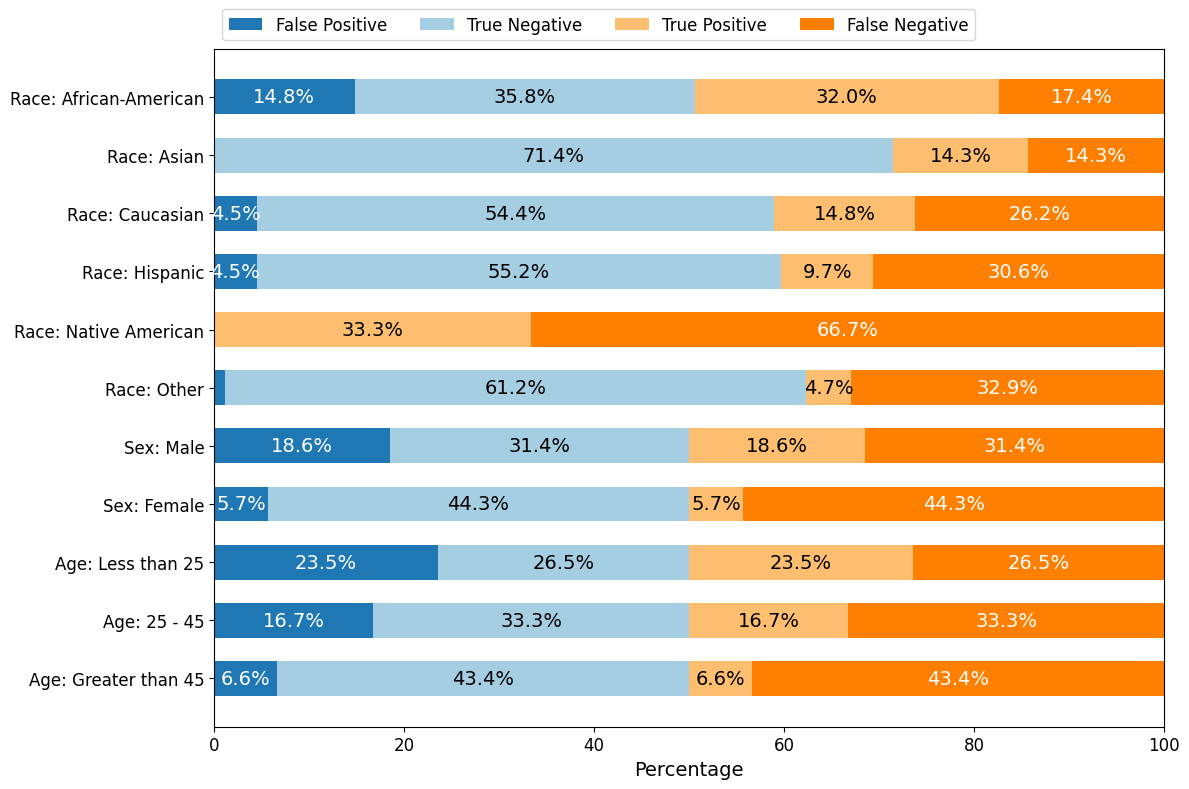

In [60]:
import matplotlib.pyplot as plt
import numpy as np
import colorsys

labels = list(TFPN_counts.keys())
data = np.array(list(TFPN_counts.values()), dtype=float)

row_totals = data.sum(axis=1, keepdims=True)
data = np.divide(data * 100, row_totals, out=np.zeros_like(data), where=row_totals != 0)

data_cum = data.cumsum(axis=1)
category_colors = plt.colormaps["Paired"].colors
category_colors = [category_colors[i] for i in [1, 0, 6, 7]]

fig, ax = plt.subplots(figsize=(12, 8))
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Percentage", fontsize=14)
ax.set_xticks(np.arange(0, 101, 20))
ax.tick_params(axis="both", labelsize=12)

for i, (colname, color) in enumerate(zip(TFPN_names, category_colors)):
    widths = data[:, i]
    starts = data_cum[:, i] - widths
    rects = ax.barh(labels, widths, left=starts, height=0.6,
                    label=colname, color=color)
    bar_labels = [f"{width:.1f}%" if width >= 4 else "" for width in widths]
    
    r, g, b = color
    text_color = "white" if colorsys.rgb_to_hls(r, g, b)[1] <= 0.5 else "black"
    ax.bar_label(rects, labels=bar_labels, label_type="center",
                 color=text_color, fontsize=14)

ax.legend(ncol=len(TFPN_names), bbox_to_anchor=(0, 1),
          loc="lower left", fontsize=12)
fig.tight_layout()
plt.show()

In [61]:
#import sqlite3
#compas = sqlite3.connect("compas.db")
#cursor = compas.cursor()
#cursor.execute(""" 
#    CREATE TABLE IF NOT EXISTS compas_data (
#        id INTEGER PRIMARY KEY,
#        sex TEXT NOT NULL CHECK (sex IN ('Male', 'Female')),
#        race TEXT NOT NULL CHECK (race IN ('African-American', 'Asian', 'Caucasian', 'Hispanic', 'Native American', 'Other')),
#        age INTEGER NOT NULL CHECK (age >= 0)
#    ) STRICT;
#""")
#compas.close()